This notebook details the study of the South Korean labor market relative to other major global markets
I plan to analyze the effect of the 52-hour work week legislation on market efficiency

### South Korea's 52-Hour Workweek Implementation Timeline

South Korea's statutory 52-hour workweek cap was phased in gradually based on firm size to mitigate operational friction across different sectors of the economy:

| Effective Date | Firm Size (Number of Employees) | Percentage of Workforce / Impact Scope |
| :--- | :--- | :--- |
| **July 1, 2018** | 300+ employees | 14% |
| **January 1, 2020** | 50–299 employees | 53% |
| **July 1, 2021** | Under 5 to 49 employees | 33% |

*Source: Ministry of Employment and Labor, South Korea / Macroeconomic Policy Archives.*

*Sources & References:* * [Korea Development Institute (KDI) Research Report](https://www.kdi.re.kr/eng/research/reportView?pub_no=18302) * [Ius Laboris Insight: South Korea's Maximum Working Week](https://iuslaboris.com/insights/south-koreas-maximum-working-week-to-be-reduced-to-52-hours/)

Imports

In [20]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
import requests 
from io import StringIO
import numpy as np
from scipy import stats

Gathering data from OECD website

In [2]:
def createurl(parts):
    return f"{server}{parts["agency"]},{parts["dataset"]},{parts["version"]}/{parts["settings"]}?{parts["date"]}{parts["format"]}"

In [3]:
server = "https://sdmx.oecd.org/public/rest/data/"
countries = "KOR+USA+DEU+JPN+MEX+OECD"
date = "startPeriod=2010"
format = "&format=csvfilewithlabels"

Annual hours dataset

In [4]:
annualhourssettings = {
    "agency": "OECD.ELS.SAE",
    "dataset": "DSD_HW@DF_AVG_ANN_HRS_WKD",
    "version": "1.0",
    "settings": f"{countries}........_T....",
    "date": date,
    "format": format,
    "columns": ["Reference area", "TIME_PERIOD", "OBS_VALUE"],
    "ylabel": "Annual Hours Worked",
}
annualhoursurl = createurl(annualhourssettings)
print(annualhoursurl)

https://sdmx.oecd.org/public/rest/data/OECD.ELS.SAE,DSD_HW@DF_AVG_ANN_HRS_WKD,1.0/KOR+USA+DEU+JPN+MEX+OECD........_T....?startPeriod=2010&format=csvfilewithlabels


Productivity dataset

In [5]:
productivitysettings = {
    "agency": "OECD.SDD.TPS",
    "dataset": "DSD_PDB@DF_PDB",
    "version": "2.0",
    "settings": f"{countries}.A.GDPHRS._T.USD_PPP_H.LR.N._Z.PPP",
    "date": date,
    "format": format,
    "columns": ["Reference area", "TIME_PERIOD", "OBS_VALUE"],
    "ylabel": "Currency Per Hour (USD)",
}
productivityurl = createurl(productivitysettings)
print(productivityurl)

https://sdmx.oecd.org/public/rest/data/OECD.SDD.TPS,DSD_PDB@DF_PDB,2.0/KOR+USA+DEU+JPN+MEX+OECD.A.GDPHRS._T.USD_PPP_H.LR.N._Z.PPP?startPeriod=2010&format=csvfilewithlabels


Getting and cleaning data

In [6]:
def getcleandataset(url, settings):
    response = requests.get(url)
    df = pd.read_csv(StringIO(response.text))
    df = df[settings["columns"]].dropna()
    return df

In [ ]:
hoursdf = getcleandataset(annualhoursurl, annualhourssettings)
hoursdf.head(3)

,Reference area,TIME_PERIOD,OBS_VALUE
0,Germany,2010,1425.4
1,Germany,2011,1427.2
2,Germany,2012,1406.0


In [8]:
proddf = getcleandataset(productivityurl, productivitysettings)
proddf.head(3)

,Reference area,TIME_PERIOD,OBS_VALUE
0,Germany,2015,78.484932
1,OECD,2019,61.186765
2,OECD,2017,59.696582


In [9]:
def getpivot(df):
    return df.pivot(index = "TIME_PERIOD", columns = "Reference area", values = "OBS_VALUE")

In [ ]:
hourspivot = getpivot(hoursdf)
prodpivot = getpivot(proddf)

Reference area  Germany   Japan   Korea  Mexico      OECD  United States
TIME_PERIOD                                                             
2010             1425.4  1733.0  2163.0  2253.5  1795.965       1810.388
2011             1427.2  1728.0  2136.0  2247.5  1797.668       1820.304
2012             1406.0  1745.0  2119.0  2238.6  1796.727       1827.068
2013             1395.7  1734.0  2105.0  2244.2  1791.696       1825.439
2014             1400.0  1729.0  2075.0  2242.2  1790.784       1830.360


Plotting the data

In [ ]:
REFORMS = {
    2011: "40-hr week fully phased in",
    2018.5: "52-hr cap: 300+ workers",
    2020: "52-hr cap: 50-299 workers",
    2021.5: "52-hr cap: 5-49 workers",
}
DEBATE = (2010, 2012)

FOCUS = "Korea"
HIGHLIGHT = {
    "Korea": "#eb6834",         
    "Japan": "#2a78d6",          
    "United States": "#1baf7a",  
}
OECD_COLOR = "#3b3a37"          
CONTEXT_COLOR = "#c9c8c2"

def mark_debate(ax):
    ax.axvspan(*DEBATE, color="#8a8984", alpha=0.08, lw=0, zorder=0)
    ax.text(sum(DEBATE) / 2, 0.02, "hours-cap\ndebate", transform=ax.get_xaxis_transform(),
            ha="center", va="bottom", fontsize=8.5, color="#52514e")
    
def mark_reforms(ax, years=REFORMS, label=True):
    for yr, text in years.items():
        ax.axvline(yr, color=HIGHLIGHT[FOCUS], ls=":", lw=1.2, alpha=0.8, zorder=0)
        if label:
            ax.text(yr + 0.15, 0.98, text, transform=ax.get_xaxis_transform(),
                    fontsize=8.5, color="#52514e", va="top", rotation=90)
def color_of(country):
    if country in HIGHLIGHT:
        return HIGHLIGHT[country]
    return OECD_COLOR if country == "OECD" else CONTEXT_COLOR

In [16]:
def plotdata(df, settings):   
    ylabel = settings["ylabel"]
    fig, ax = plt.subplots(figsize = (10, 5))
    for country in df.columns:
        ax.plot(df.index, df[country], label = country, color = color_of(country))
    mark_reforms(ax)
    mark_debate(ax)
    ax.set_title(f"{ylabel} Per Worker")
    ax.set_xlabel("Year")
    ax.set_ylabel(ylabel)
    plt.legend()
    plt.show()

Plotting annual hours worked per worker per year with the reform and debate times marked.
Observations:
The average hours worked per worker went down slightly for average countries but much more for Korea

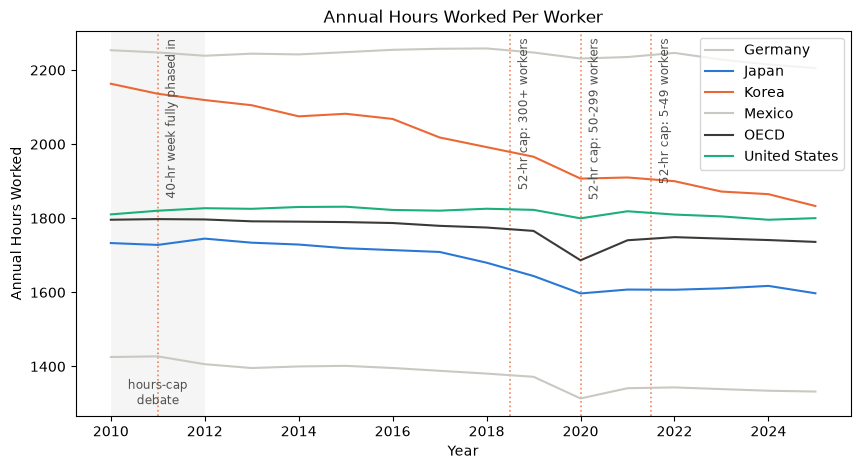

In [17]:
plotdata(hourspivot, annualhourssettings)

Plotting currency per hour per worker in USD with debate and reform times marked.
Observations:
On average, the currency per hour per worker went up, but Korea went up slightly more than average. Korea also seems to have a similar trend to the USA.

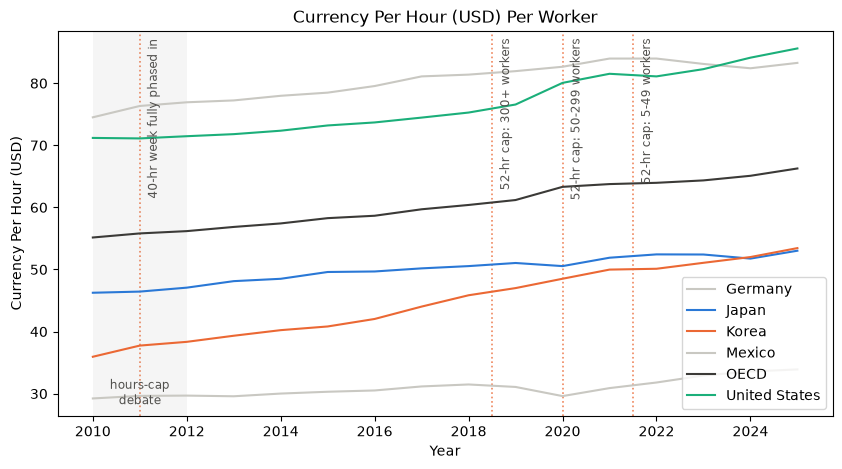

In [18]:
plotdata(prodpivot, productivitysettings)

Comparing hours worked to currency per hour during 2010-2025 for 5 major countries
Observations:
Korea seems to have had the largest shift in terms of decrease in annual hours worked per worker out of the countries plotted and more than the OECD average. It also seems to have had a large increase in currency per hours worked corresponding to the decrease in annual hours worker per worker. The overall trend seems to be that annual hours worked per worker went down while currency per hour went up, and this is most prominently seen in Shouth Korea.

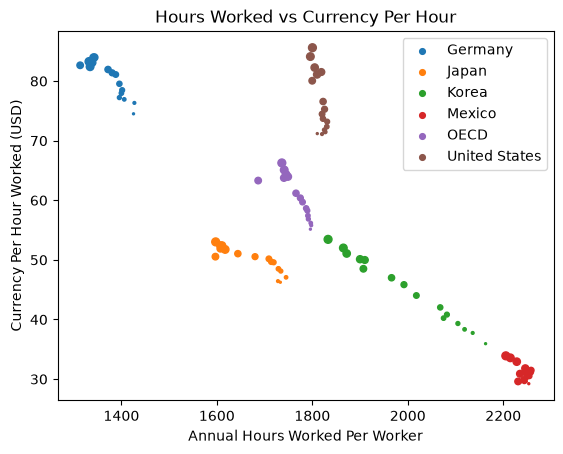

In [14]:
mergeddf = hoursdf.merge(proddf, on = ["Reference area", "TIME_PERIOD"])
mergeddf.head(20)
for country, data in mergeddf.groupby("Reference area"):
    plt.scatter(data["OBS_VALUE_x"], data["OBS_VALUE_y"], s = (data["TIME_PERIOD"] - 2009) * 2, label = country)
plt.xlabel("Annual Hours Worked Per Worker")
plt.ylabel("Currency Per Hour Worked (USD)")
plt.title("Hours Worked vs Currency Per Hour")
plt.legend()
plt.show()

In [26]:
def plotdatawithtrend(df, settings, timerange, trendvalue):   
    hours = df[trendvalue]
    timeperiod = hours.loc[timerange[0]: timerange[1]]
    years = np.arange(timerange[0], hours.index.max() + 1)
    fit = stats.linregress(timeperiod.index, np.log(timeperiod.values))
    trendlineyears = pd.Series(np.exp(fit.intercept + fit.slope * years), index = years)
    ylabel = settings["ylabel"]
    fig, ax = plt.subplots(figsize = (10, 5))
    for country in df.columns:
        if country == trendvalue:
            ax.plot(df.index, df[country], label = country, color = color_of(country))
    ax.plot(trendlineyears.index, trendlineyears.values, color = "black", ls = "--")
    mark_reforms(ax)
    mark_debate(ax)
    ax.set_title(f"{ylabel} Per Worker")
    ax.set_xlabel("Year")
    ax.set_ylabel(ylabel)
    plt.legend()
    plt.show()

Plotting the annual hours worked per worker of the OECD average and Korea from 2010-2025 with 2011-2017 trendlines to see if the change differed following the 52-hour cap implimentation.
Observations: 
Although Korea seems to have decreased more than the trendline, the overall change in the OECD average is similar as well. 

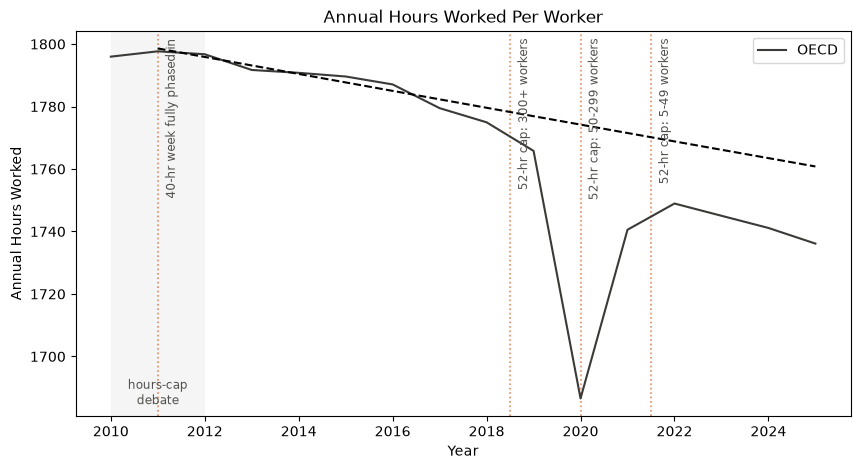

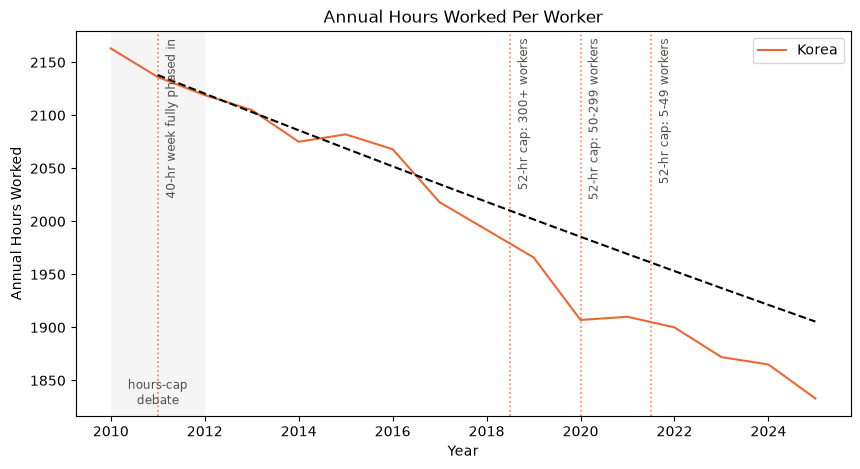

In [30]:
plotdatawithtrend(hourspivot, annualhourssettings, [2011, 2017], "OECD")
plotdatawithtrend(hourspivot, annualhourssettings, [2011, 2017], "Korea")